# Human PBMC Sequencing Techs - scVI Default vs Best UMAP

Fixed seed: `3`. Left column: cell type. Right column: batch.
Default is the top row and Best is the bottom row. Each column uses one shared legend.

Selection deltas for this seed: bio `+0.004033`,
batch `+0.184322`, joint `+0.076148`.


In [1]:
import gc
import inspect
import json
import os
import sys
from pathlib import Path

os.environ["PYTHONNOUSERSITE"] = "1"
PROJECT_ROOT = (
    "/ubc/cs/research/beaver/projects/"
    "Single-cell-integration-metrics"
)
os.environ["R_HOME"] = (
    f"{PROJECT_ROOT}/CondaEnv/scvi_py310/lib/R"
)
os.environ["R_LIBS_SITE"] = (
    f"{PROJECT_ROOT}/CondaEnv/harmony_optuna/lib/R/library"
)
sys.path.insert(0, f"{PROJECT_ROOT}/scib")

OPTIMIZER_PATH = Path(
    PROJECT_ROOT,
    "scripts",
    "optuna_multi_metrics",
    "optuna_scvi",
    "optimize_scvi_multi_metrics.py",
)
sys.path.insert(0, str(OPTIMIZER_PATH.parent))

import anndata as ad
import numpy as np
import pandas as pd
import torch
import optimize_scvi_multi_metrics as scvi_workflow

assert Path(scvi_workflow.__file__).resolve() == OPTIMIZER_PATH


In [2]:
DATASET_NAME = 'human_pbmc_sequencing_techs'
DATA_PATH = f"{PROJECT_ROOT}/data/{DATASET_NAME}.h5ad"
BATCH_KEYS = ('Method',)
BATCH_KEY = BATCH_KEYS[0]
LABEL_KEY = 'CellType'

SELECTED_BIO_METRICS = ('BAMI', 'CASW', 'SCGRAPHM', 'ISOLISI')
SELECTED_BATCH_METRICS = ('BRAS', 'KBET', 'CPCR')
SELECTED_METRICS = SELECTED_BIO_METRICS + SELECTED_BATCH_METRICS

N_SEEDS = 10
N_NEIGHBORS = 15
USE_HVG = True
N_TOP_HVG = 2000
MAX_EPOCHS = 400

EMBED_KEY = "X_scvi"
CLUSTER_KEY = "leiden_opt"
METRIC_BATCH_KEY = "scvi_metric_batch"
METRIC_LABEL_KEY = "scvi_metric_label"

assert DATASET_NAME == 'human_pbmc_sequencing_techs'
assert BATCH_KEYS == ('Method',)
assert LABEL_KEY == 'CellType'
assert SELECTED_METRICS == ('BAMI', 'CASW', 'SCGRAPHM', 'ISOLISI', 'BRAS', 'KBET', 'CPCR')

pd.Series(
    {
        "dataset": DATASET_NAME,
        "data_path": DATA_PATH,
        "batch_keys": list(BATCH_KEYS),
        "label_key": LABEL_KEY,
        "metrics": list(SELECTED_METRICS),
        "seeds": list(range(N_SEEDS)),
        "use_hvg": USE_HVG,
        "n_top_hvg": N_TOP_HVG,
        "max_epochs": MAX_EPOCHS,
    },
    name="configuration",
)


dataset                             human_pbmc_sequencing_techs
data_path     /ubc/cs/research/beaver/projects/Single-cell-i...
batch_keys                                             [Method]
label_key                                              CellType
metrics       [BAMI, CASW, SCGRAPHM, ISOLISI, BRAS, KBET, CPCR]
seeds                            [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
use_hvg                                                    True
n_top_hvg                                                  2000
max_epochs                                                  400
Name: configuration, dtype: object

In [3]:
from pathlib import Path
import anndata as ad
import matplotlib.pyplot as plt
import scanpy as sc
from IPython.display import Image, display
from matplotlib.lines import Line2D

METHOD_NAME = 'scVI'
DATASET_DISPLAY = 'Human PBMC Sequencing Techs'
SEED = 3
UMAP_ROOT = Path(
    PROJECT_ROOT,
    "notebooks",
    "optuna_multimetrics_tests",
    "UMAP",
)
FIGURE_ROOT = UMAP_ROOT / "figures"
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
FIGURE_STEM = 'human_pbmc_sequencing_techs_scvi_seed3_default_vs_best_umap'
PNG_PATH = FIGURE_ROOT / f"{FIGURE_STEM}.png"
SVG_PATH = FIGURE_ROOT / f"{FIGURE_STEM}.svg"

assert DATASET_NAME == 'human_pbmc_sequencing_techs'
assert SEED == 3

pd.Series(
    {
        "dataset": DATASET_NAME,
        "method": METHOD_NAME,
        "seed": SEED,
        "cell_type_key": LABEL_KEY,
        "batch_key": BATCH_KEY,
        "embedding_key": EMBED_KEY,
        "png": str(PNG_PATH),
        "svg": str(SVG_PATH),
    },
    name="umap_configuration",
)


dataset                                human_pbmc_sequencing_techs
method                                                        scVI
seed                                                             3
cell_type_key                                             CellType
batch_key                                                   Method
embedding_key                                               X_scvi
png              /ubc/cs/research/beaver/projects/Single-cell-i...
svg              /ubc/cs/research/beaver/projects/Single-cell-i...
Name: umap_configuration, dtype: object

In [4]:
scvi_workflow.DATA_PATH = DATA_PATH
scvi_workflow.DATASET_NAME = DATASET_NAME
scvi_workflow.BATCH_KEYS = list(BATCH_KEYS)
scvi_workflow.BATCH_KEY = BATCH_KEY
scvi_workflow.LABEL_KEY = LABEL_KEY
scvi_workflow.USE_HVG = USE_HVG
scvi_workflow.N_TOP_HVG = N_TOP_HVG
scvi_workflow.MAX_EPOCHS = MAX_EPOCHS
scvi_workflow.N_NEIGHBORS = N_NEIGHBORS
scvi_workflow.EMBED_KEY = EMBED_KEY
scvi_workflow.CLUSTER_KEY = CLUSTER_KEY
scvi_workflow.METRIC_BATCH_KEY = METRIC_BATCH_KEY
scvi_workflow.METRIC_LABEL_KEY = METRIC_LABEL_KEY

scvi_workflow.USE_BAMI = "BAMI" in SELECTED_METRICS
scvi_workflow.USE_CASW = "CASW" in SELECTED_METRICS
scvi_workflow.USE_SCGRAPHM = "SCGRAPHM" in SELECTED_METRICS
scvi_workflow.USE_TRAJ = "TRAJ" in SELECTED_METRICS
scvi_workflow.USE_ISOLISI = "ISOLISI" in SELECTED_METRICS
scvi_workflow.USE_BRAS = "BRAS" in SELECTED_METRICS
scvi_workflow.USE_KBET = "KBET" in SELECTED_METRICS
scvi_workflow.USE_CPCR = "CPCR" in SELECTED_METRICS

scvi_workflow.validate_configuration(SELECTED_METRICS)
scvi_workflow.validate_dataset_contents()

pd.Series(
    {
        "optimizer": str(OPTIMIZER_PATH),
        "scvi_version": scvi_workflow.scvi.__version__,
        "cuda_available": torch.cuda.is_available(),
    },
    name="preflight",
)


Dataset preflight: n_obs=30975 n_batches=9 n_labels=9 counts_layer=True
ISOLISI preflight: min_batch_coverage=6 isolated_labels=['Plasmacytoid dendritic cell']
CPCR preflight: eligible_labels=9


optimizer         /ubc/cs/research/beaver/projects/Single-cell-i...
scvi_version                                                  1.3.3
cuda_available                                                 True
Name: preflight, dtype: object

In [5]:
constructor_signature = inspect.signature(
    scvi_workflow.scvi.model.SCVI.__init__
)
training_signature = inspect.signature(
    scvi_workflow.scvi.train.TrainingPlan.__init__
)
assert scvi_workflow.scvi.__version__ == "1.3.3"
assert constructor_signature.parameters["n_latent"].default == 10
assert constructor_signature.parameters["n_hidden"].default == 128
assert constructor_signature.parameters["n_layers"].default == 1
assert constructor_signature.parameters["dropout_rate"].default == 0.1
assert training_signature.parameters["lr"].default == 0.001

SCVI_PARAMS = {'n_latent': 10, 'n_hidden': 128, 'n_layers': 1, 'dropout_rate': 0.1, 'lr': 0.001}
assert tuple(SCVI_PARAMS) == ('n_latent', 'n_hidden', 'n_layers', 'dropout_rate', 'lr')

pd.Series(
    {
        **SCVI_PARAMS,
        "gene_likelihood": "zinb",
        "dispersion": "gene",
        "latent_distribution": "normal",
        "early_stopping": True,
        "max_epochs": MAX_EPOCHS,
        "use_hvg": USE_HVG,
        "n_top_hvg": N_TOP_HVG,
    },
    name="default_setting",
)

def run_scvi_setting(adata, seed):
    return scvi_workflow.run_scvi(
        adata,
        n_latent=SCVI_PARAMS["n_latent"],
        n_hidden=SCVI_PARAMS["n_hidden"],
        n_layers=SCVI_PARAMS["n_layers"],
        dropout_rate=SCVI_PARAMS["dropout_rate"],
        lr=SCVI_PARAMS["lr"],
        seed=int(seed),
    )


In [6]:
print(f"Running Default with seed {SEED}", flush=True)
adata_default = run_scvi_setting(
    ad.read_h5ad(DATA_PATH),
    seed=SEED,
)
assert EMBED_KEY in adata_default.obsm
assert adata_default.obsm[EMBED_KEY].shape[0] == adata_default.n_obs
assert np.isfinite(adata_default.obsm[EMBED_KEY]).all()
adata_default


Running Default with seed 3


[rank: 0] Seed set to 3


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


...

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/CondaEnv/scvi_py310/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/CondaEnv/scvi_py310/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


Training:   0%|          | 0/400 [00:00<?, ?it/s]

Monitored metric elbo_validation did not improve in the last 45 records. Best score: 676.155. Signaling Trainer to stop.


AnnData object with n_obs × n_vars = 30975 × 33694
    obs: 'nGene', 'nUMI', 'percent.mito', 'Cluster', 'CellType', 'Experiment', 'Method'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'seurat_v3_highly_variable', 'dispersions', 'dispersions_norm'
    uns: 'CellType_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'species', 'umap'
    obsm: 'X_pca', 'X_umap', 'X_scvi'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [7]:
OPTUNA_BEST_SOURCE = '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/optuna_multi_metrics/scvi/human_pbmc_sequencing_techs/expanded_metrics_v1/scvi_human_pbmc_sequencing_techs_joint_expanded_metrics_v1_best_params.json'
OPTUNA_TRIALS_SOURCE = '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/optuna_multi_metrics/scvi/human_pbmc_sequencing_techs/expanded_metrics_v1/scvi_human_pbmc_sequencing_techs_joint_expanded_metrics_v1_trials.csv'
OPTUNA_STUDY_NAME = 'scvi_human_pbmc_sequencing_techs_joint_expanded_metrics_v1'
OPTUNA_BEST_TRIAL = 226
OPTUNA_BEST_VALUE = 0.7302770897397376
OPTUNA_BEST_PARAMS = {'n_latent': 30, 'n_hidden': 64, 'n_layers': 2, 'dropout_rate': 0.02295904871548563, 'lr': 0.0011622197032653732}

with open(OPTUNA_BEST_SOURCE, "r", encoding="utf-8") as source_file:
    current_source = json.load(source_file)
assert current_source["study_name"] == OPTUNA_STUDY_NAME
assert current_source["dataset_name"] == DATASET_NAME
assert current_source["best_value"] == OPTUNA_BEST_VALUE
assert current_source["best_params"] == OPTUNA_BEST_PARAMS
assert tuple(OPTUNA_BEST_PARAMS) == ('n_latent', 'n_hidden', 'n_layers', 'dropout_rate', 'lr')

SCVI_PARAMS = dict(OPTUNA_BEST_PARAMS)

pd.Series(
    {
        "source": OPTUNA_BEST_SOURCE,
        "trials_source": OPTUNA_TRIALS_SOURCE,
        "study": OPTUNA_STUDY_NAME,
        "best_trial": OPTUNA_BEST_TRIAL,
        "best_value": OPTUNA_BEST_VALUE,
        **SCVI_PARAMS,
        "gene_likelihood": "zinb",
        "dispersion": "gene",
        "latent_distribution": "normal",
        "early_stopping": True,
        "max_epochs": MAX_EPOCHS,
        "use_hvg": USE_HVG,
        "n_top_hvg": N_TOP_HVG,
    },
    name="best_setting",
)

def run_scvi_setting(adata, seed):
    return scvi_workflow.run_scvi(
        adata,
        n_latent=SCVI_PARAMS["n_latent"],
        n_hidden=SCVI_PARAMS["n_hidden"],
        n_layers=SCVI_PARAMS["n_layers"],
        dropout_rate=SCVI_PARAMS["dropout_rate"],
        lr=SCVI_PARAMS["lr"],
        seed=int(seed),
    )


In [8]:
print(f"Running Best with seed {SEED}", flush=True)
adata_best = run_scvi_setting(
    ad.read_h5ad(DATA_PATH),
    seed=SEED,
)
assert EMBED_KEY in adata_best.obsm
assert adata_best.obsm[EMBED_KEY].shape[0] == adata_best.n_obs
assert np.isfinite(adata_best.obsm[EMBED_KEY]).all()
adata_best


Running Best with seed 3


[rank: 0] Seed set to 3


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/CondaEnv/scvi_py310/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/CondaEnv/scvi_py310/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


Training:   0%|          | 0/400 [00:00<?, ?it/s]

Monitored metric elbo_validation did not improve in the last 45 records. Best score: 670.187. Signaling Trainer to stop.


AnnData object with n_obs × n_vars = 30975 × 33694
    obs: 'nGene', 'nUMI', 'percent.mito', 'Cluster', 'CellType', 'Experiment', 'Method'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'seurat_v3_highly_variable', 'dispersions', 'dispersions_norm'
    uns: 'CellType_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'species', 'umap'
    obsm: 'X_pca', 'X_umap', 'X_scvi'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [9]:
assert adata_default.obs_names.equals(adata_best.obs_names)
assert LABEL_KEY in adata_default.obs
assert BATCH_KEY in adata_default.obs
assert adata_default.obs[LABEL_KEY].equals(adata_best.obs[LABEL_KEY])
assert adata_default.obs[BATCH_KEY].equals(adata_best.obs[BATCH_KEY])

for setting_name, adata_setting in (
    ("Default", adata_default),
    ("Best", adata_best),
):
    sc.pp.neighbors(
        adata_setting,
        n_neighbors=N_NEIGHBORS,
        use_rep=EMBED_KEY,
        random_state=SEED,
    )
    sc.tl.umap(adata_setting, random_state=SEED)
    assert "X_umap" in adata_setting.obsm
    assert np.isfinite(adata_setting.obsm["X_umap"]).all()
    print(
        setting_name,
        adata_setting.obsm["X_umap"].shape,
        flush=True,
    )


Default (30975, 2)


Best (30975, 2)


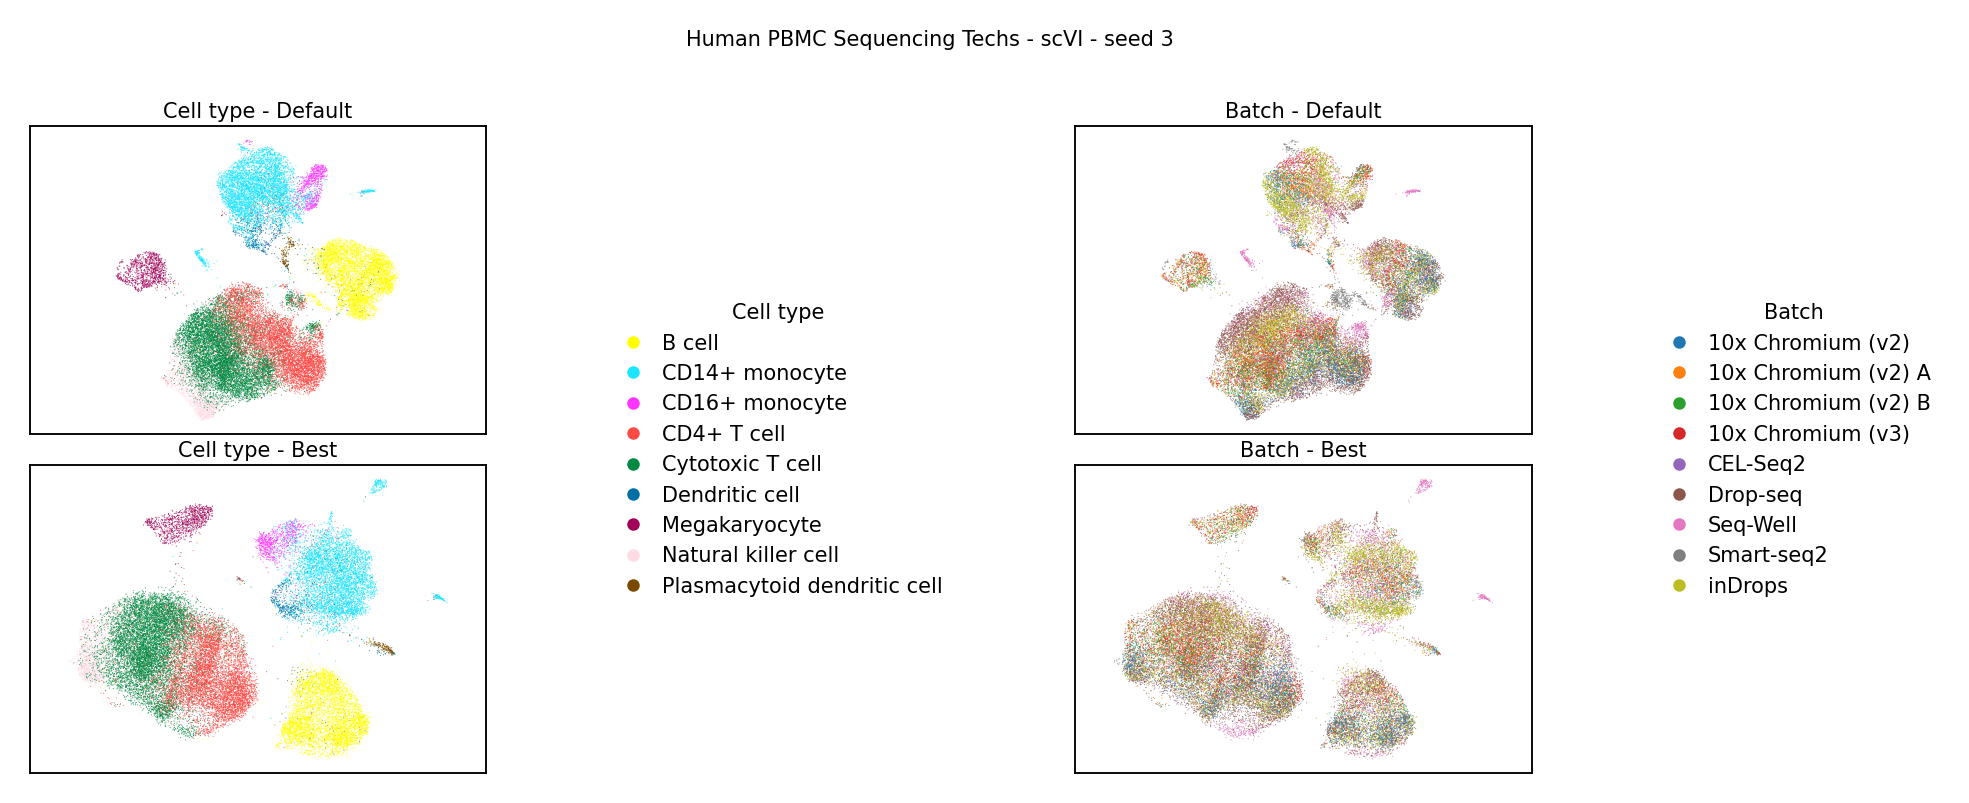

png           /ubc/cs/research/beaver/projects/Single-cell-i...
svg           /ubc/cs/research/beaver/projects/Single-cell-i...
n_cells                                                   30975
cell_types                                                    9
batches                                                       9
point_size                                                 0.07
Name: saved_figure, dtype: object

In [10]:
UMAP_SOURCE_TEXT_SIZE_PT = 5.0
UMAP_RASTER_DPI = 600


def ordered_categories(adata, key):
    values = adata.obs[key].astype(str)
    return tuple(sorted(pd.unique(values), key=str))


def category_palette(categories):
    if len(categories) <= len(sc.pl.palettes.default_102):
        colors = sc.pl.palettes.default_102[: len(categories)]
    else:
        cmap = plt.get_cmap("hsv", len(categories))
        colors = [cmap(index) for index in range(len(categories))]
    return dict(zip(categories, colors))


def scatter_panel(ax, adata, key, palette, title, order, point_size):
    values = adata.obs[key].astype(str).to_numpy()
    coordinates = adata.obsm["X_umap"]
    colors = [palette[value] for value in values[order]]
    ax.scatter(
        coordinates[order, 0],
        coordinates[order, 1],
        c=colors,
        s=point_size,
        alpha=0.78,
        linewidths=0,
        rasterized=False,
    )
    ax.set_title(
        title,
        fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
        pad=2,
    )
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.45)


def legend_handles(categories, palette):
    return [
        Line2D(
            [0],
            [0],
            marker="o",
            color="none",
            markerfacecolor=palette[category],
            markeredgecolor="none",
            markersize=3,
            label=category,
        )
        for category in categories
    ]


cell_categories = ordered_categories(adata_default, LABEL_KEY)
batch_categories = ordered_categories(adata_default, BATCH_KEY)
cell_palette = category_palette(cell_categories)
tab10_batch_colors = plt.get_cmap("tab10").colors
if len(batch_categories) > len(tab10_batch_colors):
    raise ValueError(
        "tab10 does not contain enough colors for all batch categories."
    )
batch_palette = dict(
    zip(batch_categories, tab10_batch_colors)
)

cell_legend_columns = 2 if len(cell_categories) > 18 else 1
batch_legend_columns = 2 if len(batch_categories) > 18 else 1
max_legend_rows = max(
    int(np.ceil(len(cell_categories) / cell_legend_columns)),
    int(np.ceil(len(batch_categories) / batch_legend_columns)),
)
figure_height = max(2.8, 0.18 * max_legend_rows)
figure = plt.figure(figsize=(8.0, figure_height), dpi=250)
grid = figure.add_gridspec(
    2,
    4,
    width_ratios=(1.0, 0.82, 1.0, 0.55),
    hspace=0.10,
    wspace=0.28,
)
cell_default_axis = figure.add_subplot(grid[0, 0])
cell_best_axis = figure.add_subplot(grid[1, 0])
cell_legend_axis = figure.add_subplot(grid[:, 1])
batch_default_axis = figure.add_subplot(grid[0, 2])
batch_best_axis = figure.add_subplot(grid[1, 2])
batch_legend_axis = figure.add_subplot(grid[:, 3])

plot_order = np.random.default_rng(SEED).permutation(
    adata_default.n_obs
)
if adata_default.n_obs <= 20_000:
    point_size = 0.10
elif adata_default.n_obs <= 40_000:
    point_size = 0.07
elif adata_default.n_obs <= 100_000:
    point_size = 0.05
else:
    point_size = 0.03

scatter_panel(
    cell_default_axis,
    adata_default,
    LABEL_KEY,
    cell_palette,
    "Cell type - Default",
    plot_order,
    point_size,
)
scatter_panel(
    cell_best_axis,
    adata_best,
    LABEL_KEY,
    cell_palette,
    "Cell type - Best",
    plot_order,
    point_size,
)
scatter_panel(
    batch_default_axis,
    adata_default,
    BATCH_KEY,
    batch_palette,
    "Batch - Default",
    plot_order,
    point_size,
)
scatter_panel(
    batch_best_axis,
    adata_best,
    BATCH_KEY,
    batch_palette,
    "Batch - Best",
    plot_order,
    point_size,
)

cell_legend_axis.axis("off")
cell_legend_axis.legend(
    handles=legend_handles(cell_categories, cell_palette),
    title="Cell type",
    loc="center left",
    frameon=False,
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    title_fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    ncol=cell_legend_columns,
    columnspacing=0.9,
    handletextpad=0.4,
)
batch_legend_axis.axis("off")
batch_legend_axis.legend(
    handles=legend_handles(batch_categories, batch_palette),
    title="Batch",
    loc="center left",
    frameon=False,
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    title_fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    ncol=batch_legend_columns,
    columnspacing=0.9,
    handletextpad=0.4,
)

figure.suptitle(
    f"{DATASET_DISPLAY} - {METHOD_NAME} - seed {SEED}",
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    y=0.995,
)
figure.savefig(
    PNG_PATH,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
figure.savefig(
    SVG_PATH,
    format="svg",
    dpi=UMAP_RASTER_DPI,
    bbox_inches="tight",
    facecolor="white",
)
plt.close(figure)

display(Image(filename=str(PNG_PATH)))
pd.Series(
    {
        "png": str(PNG_PATH),
        "svg": str(SVG_PATH),
        "n_cells": adata_default.n_obs,
        "cell_types": len(cell_categories),
        "batches": len(batch_categories),
        "point_size": point_size,
    },
    name="saved_figure",
)


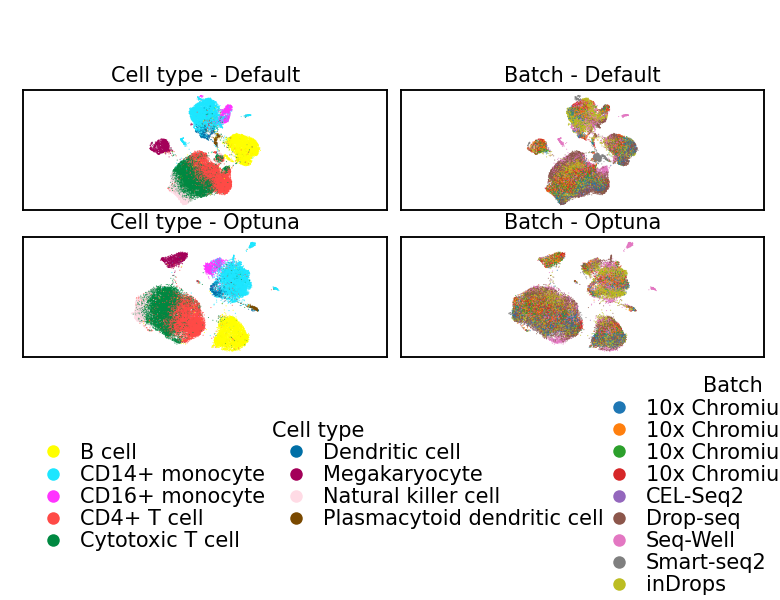

png            /ubc/cs/research/beaver/projects/Single-cell-i...
svg            /ubc/cs/research/beaver/projects/Single-cell-i...
n_cells                                                    30975
cell_types                                                     9
batches                                                        9
point_size                                                  0.07
panel_label                                               Optuna
suptitle                                                   False
Name: saved_revised_figure, dtype: object

In [11]:
revised_figure = plt.figure(
    figsize=(6.5 / 2.5, 2.0),
    dpi=250,
)
revised_grid = revised_figure.add_gridspec(
    3,
    4,
    height_ratios=(1.0, 1.0, 1.7),
    width_ratios=(1.0, 1.0, 1.0, 1.0),
    hspace=0.18,
    wspace=0.08,
)
revised_cell_default_axis = revised_figure.add_subplot(revised_grid[0, 0:2])
revised_cell_optuna_axis = revised_figure.add_subplot(revised_grid[1, 0:2])
revised_cell_legend_axis = revised_figure.add_subplot(revised_grid[2, 0:3])
revised_batch_default_axis = revised_figure.add_subplot(revised_grid[0, 2:4])
revised_batch_optuna_axis = revised_figure.add_subplot(revised_grid[1, 2:4])
revised_batch_legend_axis = revised_figure.add_subplot(revised_grid[2, 3])

scatter_panel(
    revised_cell_default_axis,
    adata_default,
    LABEL_KEY,
    cell_palette,
    "Cell type - Default",
    plot_order,
    point_size,
)
scatter_panel(
    revised_cell_optuna_axis,
    adata_best,
    LABEL_KEY,
    cell_palette,
    "Cell type - Optuna",
    plot_order,
    point_size,
)
scatter_panel(
    revised_batch_default_axis,
    adata_default,
    BATCH_KEY,
    batch_palette,
    "Batch - Default",
    plot_order,
    point_size,
)
scatter_panel(
    revised_batch_optuna_axis,
    adata_best,
    BATCH_KEY,
    batch_palette,
    "Batch - Optuna",
    plot_order,
    point_size,
)

revised_cell_legend_axis.axis("off")
revised_cell_legend_axis.legend(
    handles=legend_handles(cell_categories, cell_palette),
    title="Cell type",
    loc="center left",
    frameon=False,
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    title_fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    ncol=2,
    columnspacing=0.5,
    handletextpad=0.3,
    labelspacing=0.1,
    borderaxespad=0,
)
revised_batch_legend_axis.axis("off")
revised_batch_legend_axis.legend(
    handles=legend_handles(batch_categories, batch_palette),
    title="Batch",
    loc="center left",
    frameon=False,
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    title_fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    ncol=batch_legend_columns,
    columnspacing=0.5,
    handletextpad=0.3,
    labelspacing=0.1,
    borderaxespad=0,
)

REVISED_FIGURE_STEM = f"{FIGURE_STEM}_optuna_no_suptitle"
REVISED_PNG_PATH = FIGURE_ROOT / f"{REVISED_FIGURE_STEM}.png"
REVISED_SVG_PATH = FIGURE_ROOT / f"{REVISED_FIGURE_STEM}.svg"

revised_figure.subplots_adjust(
    left=0.03,
    right=0.98,
    bottom=0.02,
    top=0.85,
)
revised_figure.savefig(
    REVISED_PNG_PATH,
    dpi=300,
    facecolor="white",
)
revised_figure.savefig(
    REVISED_SVG_PATH,
    format="svg",
    dpi=UMAP_RASTER_DPI,
    facecolor="white",
)
plt.close(revised_figure)

display(Image(filename=str(REVISED_PNG_PATH)))
pd.Series(
    {
        "png": str(REVISED_PNG_PATH),
        "svg": str(REVISED_SVG_PATH),
        "n_cells": adata_default.n_obs,
        "cell_types": len(cell_categories),
        "batches": len(batch_categories),
        "point_size": point_size,
        "panel_label": "Optuna",
        "suptitle": False,
    },
    name="saved_revised_figure",
)
